# plot the time mean true and pred

In [5]:
# compare the npz data with data after data_loader
import torch
# path issue
import sys
from pathlib import Path
sys.path.insert(0, str(Path("/scratch/jczhang/submeso_data_driven").resolve()))

# check the velocity field and vorticity field
import numpy as np
import xarray as xr
from src.utils import read_mitgcm
from src.utils import build_coarse_grid

from matplotlib.colors import TwoSlopeNorm
from matplotlib.colors import Normalize
import cmocean.cm as cmo
import h5netcdf
import importlib
from MITgcmutils import mds
import matplotlib.pyplot as plt
# other parameters
path_scratch = '/scratch/jczhang/'
path_MITgcm = 'MITgcm_baroclinic_instability_old/MITgcm/verification/tutorial_reentrant_channel/run/'
grid_dir = path_scratch + path_MITgcm
ds_fine = read_mitgcm.read_mitgrid_staggered(grid_dir)
ds_coarse = build_coarse_grid.build_coarse_grid_staggered(ds_fine,box_j=10, box_i=10)
XC_c = ds_coarse["XC"]
YC_c = ds_coarse["YC"]

y_true_path = "../../../outputs/cfg_19/test_y_true.npy"
y_pred_path = "../../../outputs/cfg_19/test_y_pred.npy"
y_true = np.load(y_true_path)   # shape (N,1,H,W)
y_pred = np.load(y_pred_path)   # shape (N,1,H,W)

# read the norm from pt file
ckpt_path = "../../../check_point/cfg_19/best_unet_conv.pt"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
norm = ckpt["norm"]   # dict with X_mu, X_sd, y_mu, y_sd

y_mu = norm["y_mu"]   # scalar
y_sd = norm["y_sd"]   # scalar

y_true_phys = y_true * y_sd + y_mu
y_pred_phys = y_pred * y_sd + y_mu

Saved: ./time_mean_true_pred_error.png


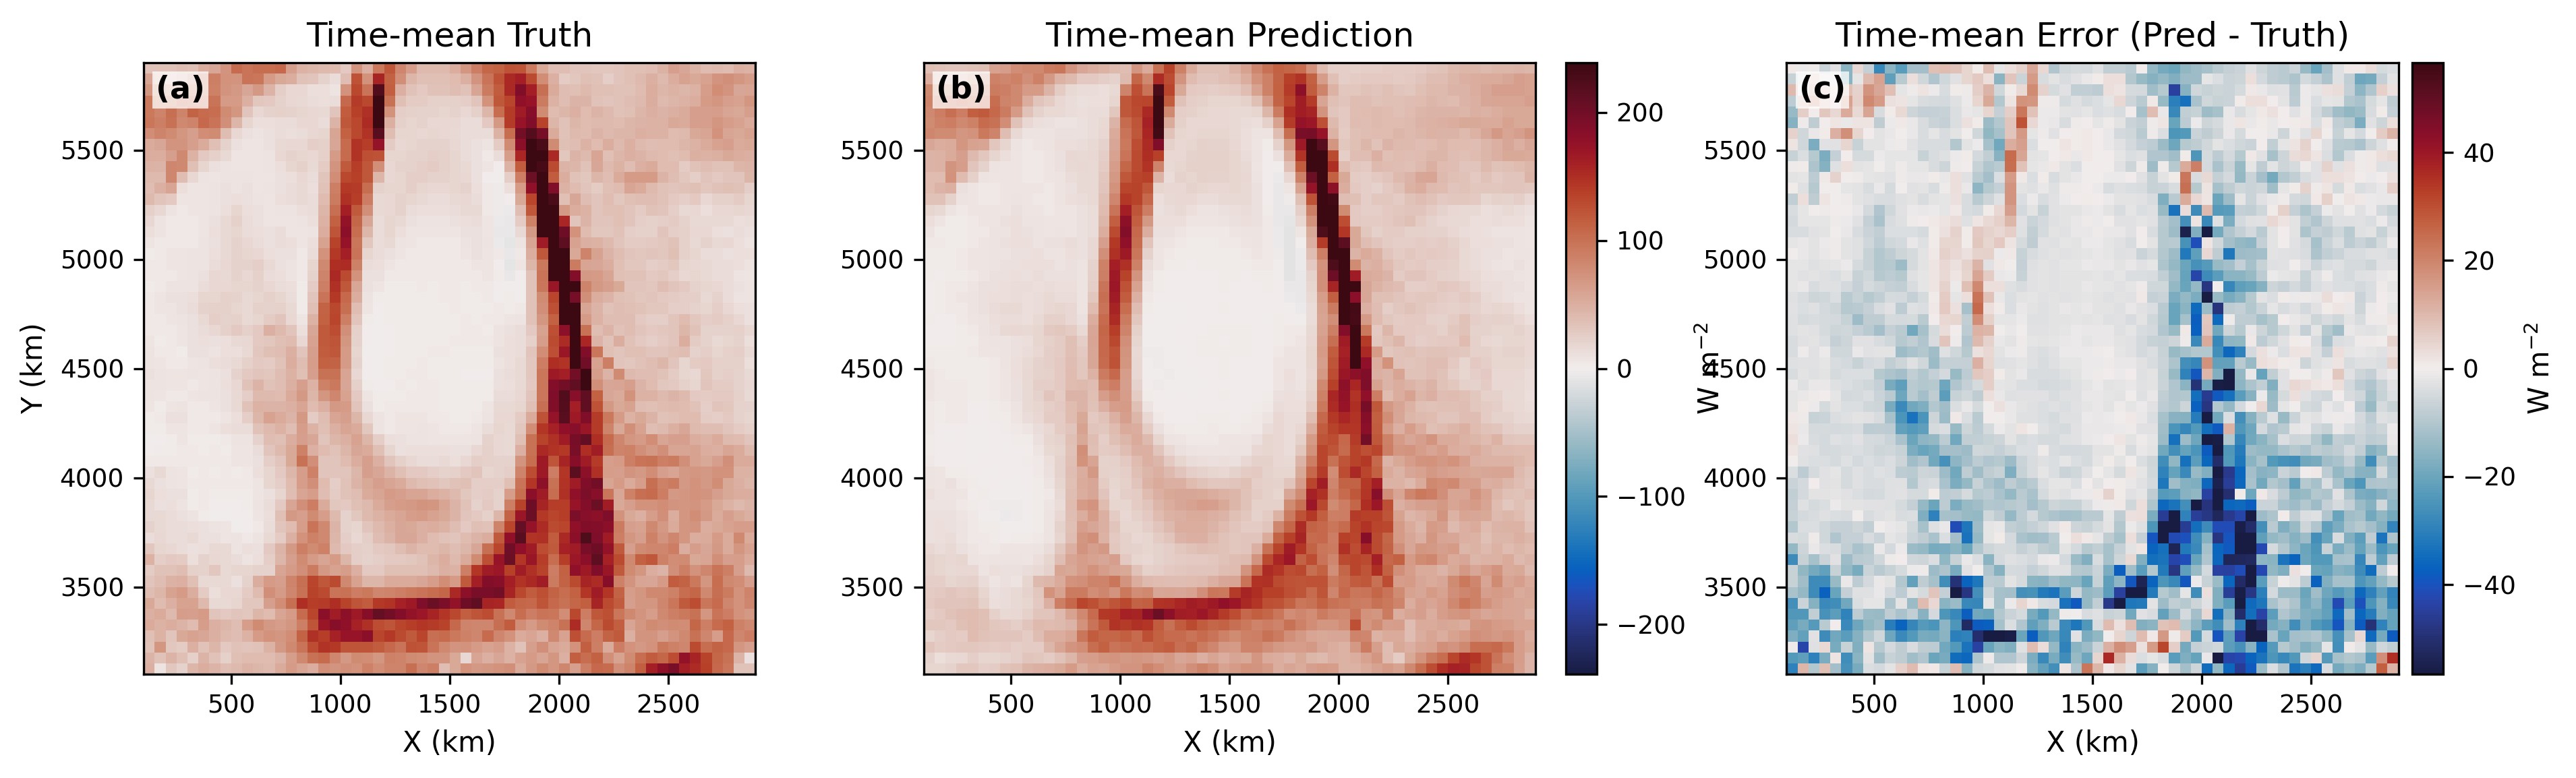

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
import cmocean.cm as cmo

def plot_time_mean_true_pred_error(
    y_true_phys, y_pred_phys,
    XC_c, YC_c,
    units=r"W m$^{-2}$",
    figsize=(13.2, 4.2),
    dpi=300,
    q_main=99,      # robust color scaling for mean fields
    q_err=99,       # robust color scaling for error
    savepath=None,
):
    """
    Plot time-mean truth, time-mean prediction, and their difference.
    Expects y_*_phys shapes (N,1,H,W) or (N,H,W).
    """
    # squeeze channel if present
    Yt = y_true_phys[:, 0] if y_true_phys.ndim == 4 else y_true_phys
    Yp = y_pred_phys[:, 0] if y_pred_phys.ndim == 4 else y_pred_phys

    # time means
    ybar_true = np.nanmean(Yt, axis=0)   # (H,W)
    ybar_pred = np.nanmean(Yp, axis=0)   # (H,W)
    ybar_err  = ybar_pred - ybar_true

    # coords in km
    x = np.asarray(XC_c, dtype=float) / 1000.0
    y = np.asarray(YC_c, dtype=float) / 1000.0

    # robust symmetric color scale for signed mean fields
    pool = np.concatenate([
        ybar_true[np.isfinite(ybar_true)].ravel(),
        ybar_pred[np.isfinite(ybar_pred)].ravel()
    ])
    vabs_main = np.nanpercentile(np.abs(pool), q_main)
    norm_main = TwoSlopeNorm(vmin=-vabs_main, vcenter=0.0, vmax=vabs_main)

    # robust symmetric color scale for error
    vabs_err = np.nanpercentile(np.abs(ybar_err[np.isfinite(ybar_err)]), q_err)
    norm_err = TwoSlopeNorm(vmin=-vabs_err, vcenter=0.0, vmax=vabs_err)

    fig, axes = plt.subplots(1, 3, figsize=figsize, dpi=dpi)
    plt.subplots_adjust(left=0.06, right=0.94, bottom=0.14, top=0.86, wspace=0.18)

    panels = [
        (ybar_true, "Time-mean Truth", norm_main, cmo.balance),
        (ybar_pred, "Time-mean Prediction", norm_main, cmo.balance),
        (ybar_err,  "Time-mean Error (Pred - Truth)", norm_err, cmo.balance),
    ]

    ims = []
    for i, (ax, (field, ttl, norm, cmap)) in enumerate(zip(axes, panels)):
        im = ax.pcolormesh(x, y, field, shading="auto", cmap=cmap, norm=norm, rasterized=True)
        ims.append(im)

        ax.set_title(ttl, fontsize=12)
        ax.set_aspect("equal")
        ax.set_xlabel("X (km)", fontsize=10)
        ax.tick_params(axis="both", labelsize=9)
        ax.set_ylabel("Y (km)" if i == 0 else "", fontsize=10)

        ax.text(
            0.02, 0.98, f"({chr(97+i)})",
            transform=ax.transAxes,
            ha="left", va="top",
            fontsize=11,
            fontweight="bold",
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.75, pad=1.2),
        )

    # colorbars: one for mean fields, one for error
    cbar_main = fig.colorbar(ims[0], ax=axes[:2], fraction=0.035, pad=0.02)
    cbar_main.set_label(units, fontsize=10)
    cbar_main.ax.tick_params(labelsize=9)

    cbar_err = fig.colorbar(ims[2], ax=axes[2], fraction=0.046, pad=0.02)
    cbar_err.set_label(units, fontsize=10)
    cbar_err.ax.tick_params(labelsize=9)

    if savepath is not None:
        fig.savefig(savepath, dpi=dpi, bbox_inches="tight")
        print("Saved:", savepath)

    plt.show()
    return ybar_true, ybar_pred, ybar_err

# ----------------- run it -----------------
ybar_true, ybar_pred, ybar_err = plot_time_mean_true_pred_error(
    y_true_phys=y_true_phys,
    y_pred_phys=y_pred_phys,
    XC_c=XC_c[62:118,2:58],
    YC_c=YC_c[62:118,2:58],
    units=r"W m$^{-2}$",
    q_main=99,
    q_err=99,
    savepath="./time_mean_true_pred_error.png",
)

# Test how mean R2 change with averaging time windows

In [6]:
import numpy as np
import matplotlib.pyplot as plt

def plot_r2_window_curve(
    y_true_phys,
    y_pred_phys,
    *,
    dt_hours: float = 12.0,
    windows_days=(0.5, 1, 2, 4, 7, 10, 14, 21, 30, 45, 60, 90),
    stride: int = 1,
    q_smooth: int | None = None,
    title: str = r"Mean-field $R^2$ vs averaging window",
    savepath: str | None = None,
    dpi: int = 300,
):
    """
    Compute and plot R^2_mean(W) for window-averaged maps.

    - y_true_phys, y_pred_phys: (N,1,H,W) or (N,H,W) in time order
    - windows_days: iterable of window lengths (days)
    - stride: step between window start indices (1 uses all sliding windows)
    - q_smooth: optional running-mean smoothing on the curve itself (in #windows)
    """
    # squeeze channel dim
    Yt = y_true_phys[:, 0] if y_true_phys.ndim == 4 else y_true_phys
    Yp = y_pred_phys[:, 0] if y_pred_phys.ndim == 4 else y_pred_phys
    assert Yt.shape == Yp.shape and Yt.ndim == 3, f"Expect (N,H,W). Got {Yt.shape} vs {Yp.shape}"

    N = Yt.shape[0]
    dt_days = dt_hours / 24.0

    def r2_map(a, b, eps=1e-12):
        aa = np.asarray(a, float).ravel()
        bb = np.asarray(b, float).ravel()
        m = np.isfinite(aa) & np.isfinite(bb)
        aa = aa[m]; bb = bb[m]
        if aa.size < 2:
            return np.nan
        sse = np.sum((bb - aa) ** 2)
        sst = np.sum((aa - aa.mean()) ** 2)
        return 1.0 - sse / (sst + eps)

    W_days = []
    R2W = []
    nwin_used = []

    for wd in windows_days:
        W = int(round(wd / dt_days))
        if W < 1:
            W = 1
        if W > N:
            continue

        starts = np.arange(0, N - W + 1, stride, dtype=int)
        r2_list = []

        for s in starts:
            yt_bar = np.nanmean(Yt[s:s+W], axis=0)
            yp_bar = np.nanmean(Yp[s:s+W], axis=0)
            r2_list.append(r2_map(yt_bar, yp_bar))

        r2_list = np.asarray(r2_list, float)
        W_days.append(W * dt_days)
        R2W.append(np.nanmean(r2_list))
        nwin_used.append(int(np.isfinite(r2_list).sum()))

    W_days = np.asarray(W_days)
    R2W = np.asarray(R2W)

    # optional smoothing of the curve (not required)
    if q_smooth is not None and q_smooth > 1 and R2W.size >= q_smooth:
        k = np.ones(q_smooth) / q_smooth
        R2W_s = np.convolve(R2W, k, mode="same")
    else:
        R2W_s = None

    # plot
    plt.figure(figsize=(7.2, 4.2), dpi=dpi)
    plt.plot(W_days, R2W, marker="o", linewidth=1.5, label=r"$R^2_{\mathrm{mean}}(W)$")
    if R2W_s is not None:
        plt.plot(W_days, R2W_s, linewidth=2.0, label=f"smoothed (w={q_smooth})")

    plt.xlabel("Averaging window length W (days)")
    plt.ylabel(r"$R^2_{\mathrm{mean}}(W)$")
    plt.title(title)
    plt.grid(True, alpha=0.3)
    plt.legend(frameon=False)
    plt.tight_layout()

    if savepath is not None:
        plt.savefig(savepath, dpi=dpi, bbox_inches="tight")
        print("Saved:", savepath)

    plt.show()

    # return arrays in case you want to report numbers
    return W_days, R2W, nwin_used

Saved: ./r2_mean_vs_window.png


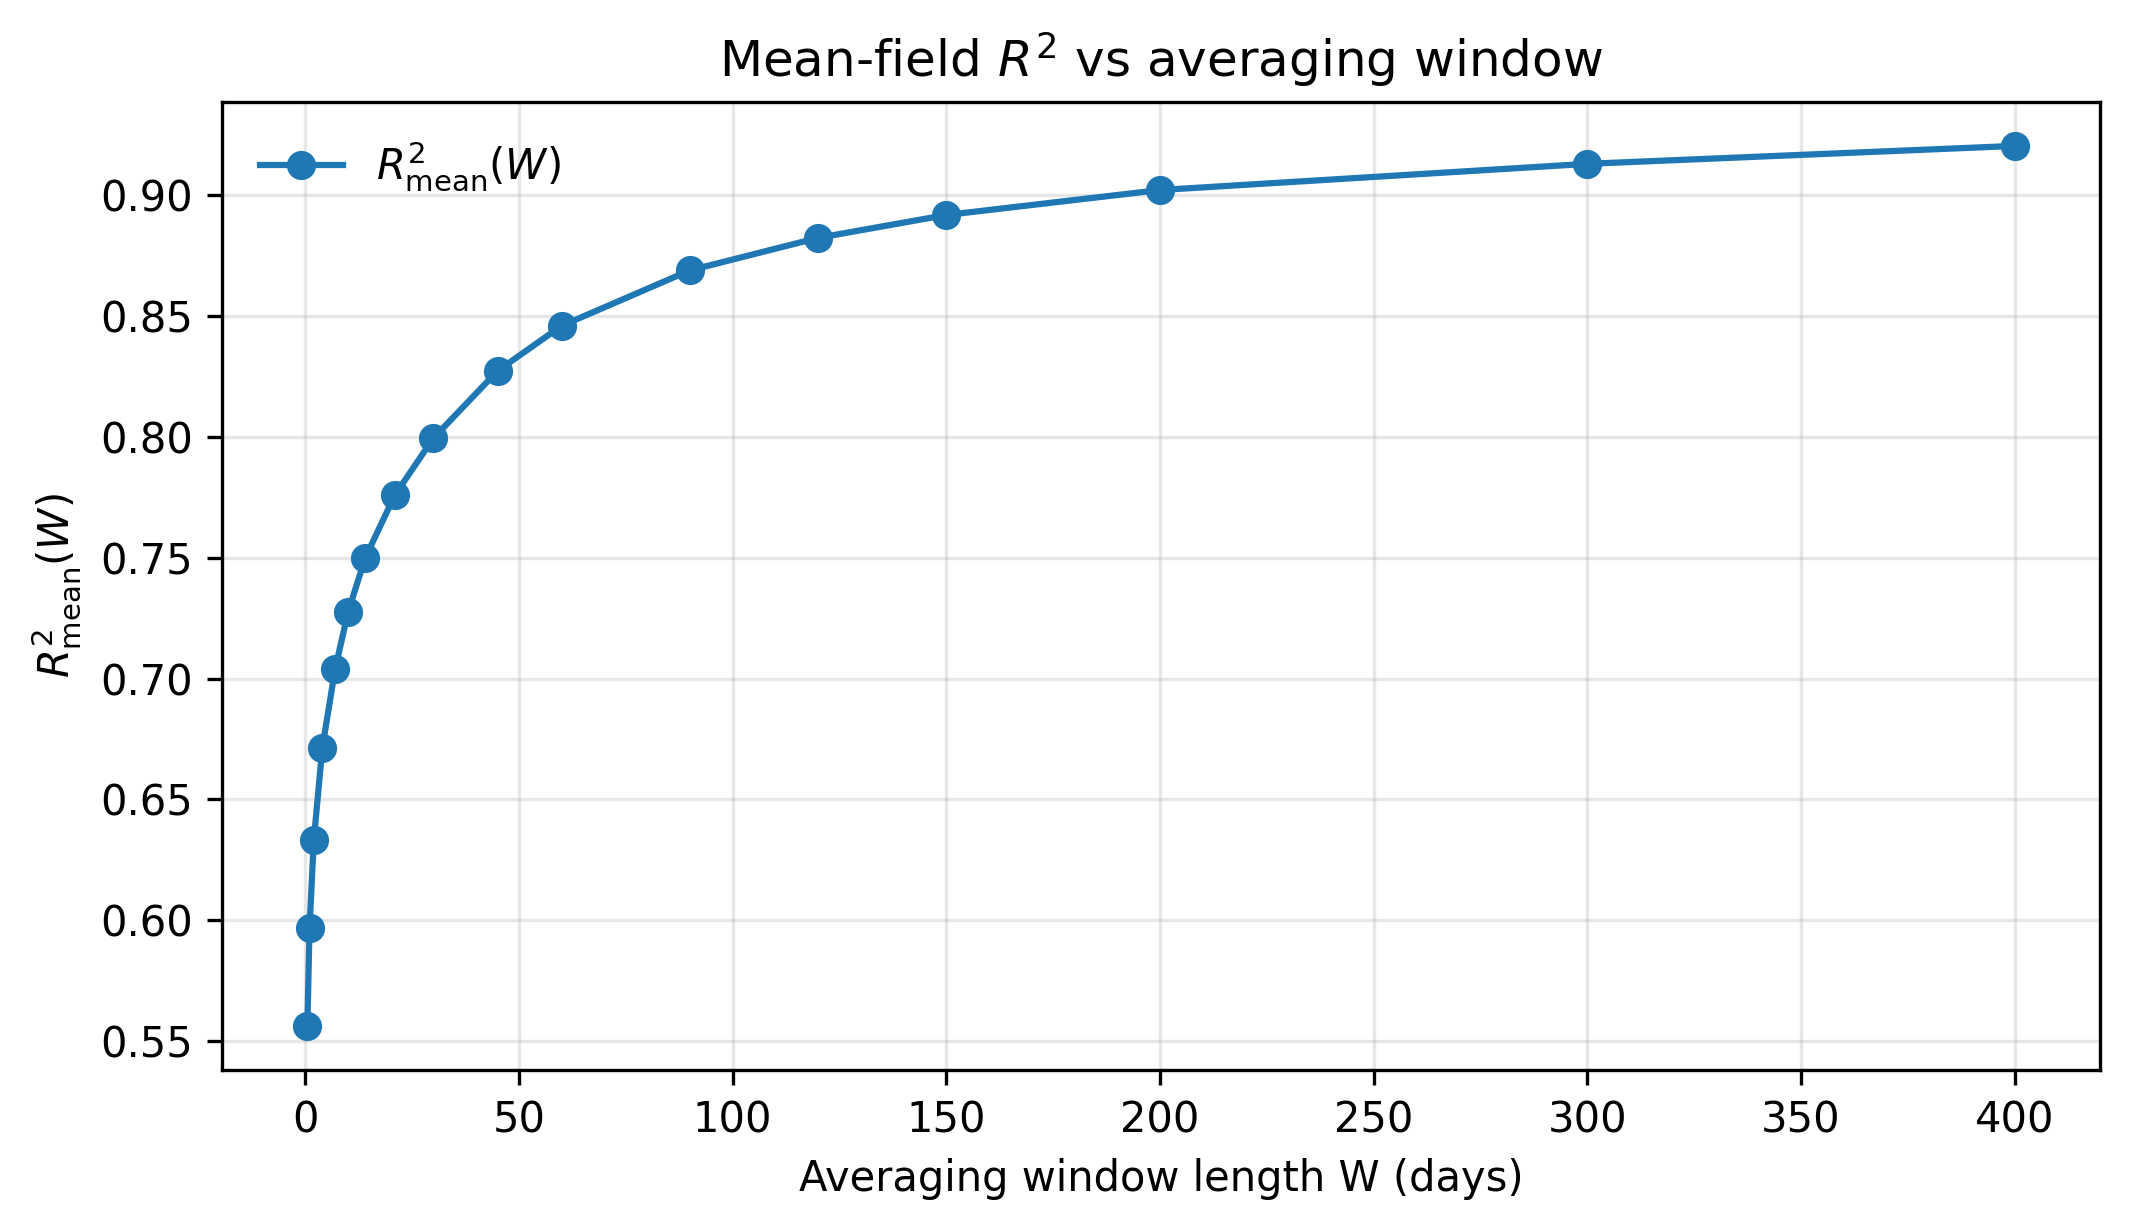

In [10]:
W_days, R2W, n_used = plot_r2_window_curve(
    y_true_phys=y_true_phys,
    y_pred_phys=y_pred_phys,
    dt_hours=12,
    windows_days=(0.5, 1, 2, 4, 7, 10, 14, 21, 30, 45, 60, 90, 120, 150, 200, 300, 400, 500, 600, 700, 800, 900),
    stride=1,
    savepath="./r2_mean_vs_window.png",
)